# Customer Segmentation Using K-Means Clustering

This project applies unsupervised machine learning to identify groups of customers with similar characteristics and spending behavior.

The goal is to discover meaningful customer segments without using predefined target labels.

## Objectives

- Explore customer demographic and spending data
- Prepare numerical features for clustering
- Standardize the selected features
- Determine an appropriate number of clusters
- Apply K-Means clustering
- Visualize and analyze customer segments
- Use PCA for two-dimensional cluster visualization

## Machine Learning Approach

The project uses **K-Means Clustering**, an unsupervised learning algorithm that groups similar observations into clusters based on their feature values.

Unlike supervised learning, this project does not use a target variable.

## 1. Import Libraries

The following libraries are used for data manipulation, visualization, preprocessing, clustering, evaluation, and dimensionality reduction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## 2. Load the Dataset

The dataset contains information about mall customers, including their age, annual income, and spending score.

The dataset is stored locally in the `data` directory.

In [2]:
df = pd.read_csv("data/Mall_Customers.csv")

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Understand the Dataset

Before applying clustering, we inspect the dataset structure, data types, dimensions, and summary statistics.

In [3]:
print("Dataset shape:", df.shape)

df.info()

Dataset shape: (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


### Summary Statistics

The summary statistics provide information about the distribution of the numerical features.

In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Missing Values

We check for missing values to ensure the dataset is ready for further analysis.

In [5]:
df.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

## 4. Exploratory Data Analysis

Exploratory data analysis helps us understand the characteristics and distributions of the customers before applying the clustering algorithm.

### Age Distribution

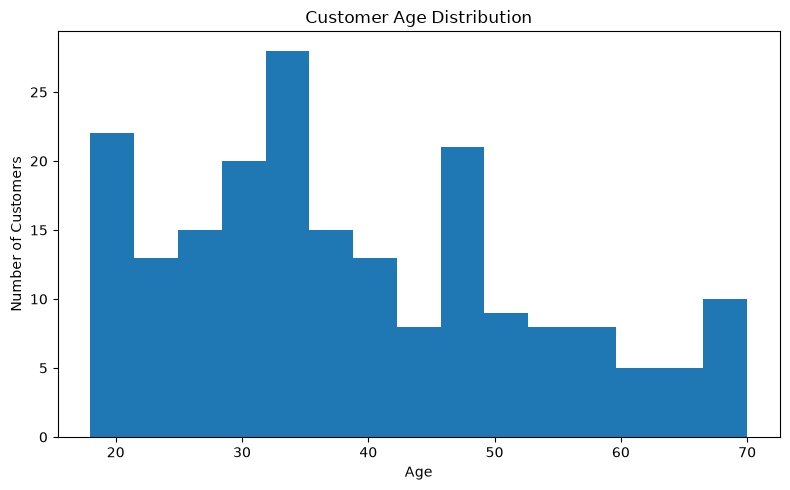

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=15)

plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.title("Customer Age Distribution")

plt.tight_layout()
plt.show()

### Annual Income Distribution

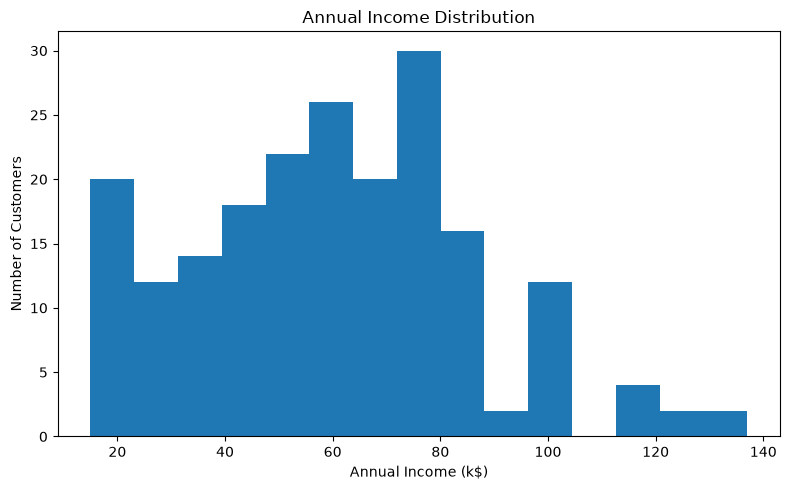

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["Annual Income (k$)"], bins=15)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.title("Annual Income Distribution")

plt.tight_layout()
plt.show()

### Spending Score Distribution

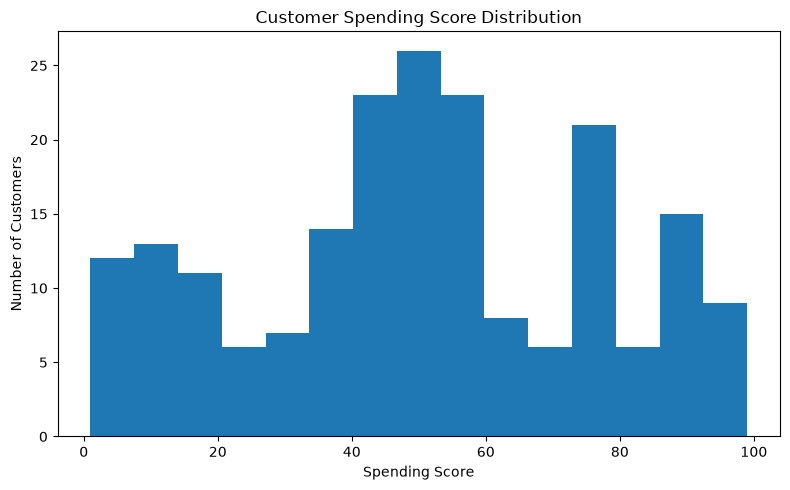

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(df["Spending Score (1-100)"], bins=15)

plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")
plt.title("Customer Spending Score Distribution")

plt.tight_layout()
plt.show()

### Annual Income vs Spending Score

Annual income and spending score are useful variables for identifying differences in customer purchasing behavior.

The scatter plot helps us visually examine whether customers naturally form groups based on these features.

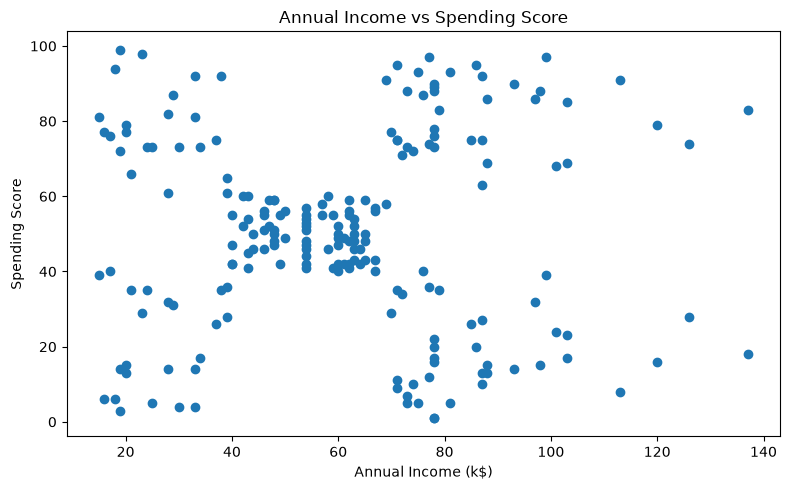

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"]
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Annual Income vs Spending Score")

plt.tight_layout()
plt.show()

## 5. Feature Selection

The following numerical features will be used for clustering:

- Age
- Annual Income
- Spending Score

`CustomerID` is excluded because it is only an identifier and does not represent a meaningful customer characteristic.

`Gender` is excluded from the initial clustering model so that the segmentation focuses on numerical demographic and spending characteristics.

In [10]:
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features]

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [11]:
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Number of samples: 200
Number of features: 3


## 6. Feature Scaling

K-Means clustering is based on distances between observations.

Because the selected features have different numerical ranges, the features are standardized using `StandardScaler`.

This gives each feature a comparable scale and prevents features with larger numerical values from dominating the distance calculations.

In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992]])

## 7. Finding the Optimal Number of Clusters

K-Means requires us to specify the number of clusters before training the model.

To determine a suitable value for `K`, we will use:

1. The Elbow Method
2. The Silhouette Score

Using both methods provides additional evidence when selecting the number of clusters.

### Elbow Method

The Elbow Method evaluates the K-Means inertia for different numbers of clusters.

Inertia measures the total squared distance between observations and their assigned cluster centers.

As the number of clusters increases, inertia decreases. We look for a point where the improvement begins to slow down significantly.

In [13]:
inertia = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

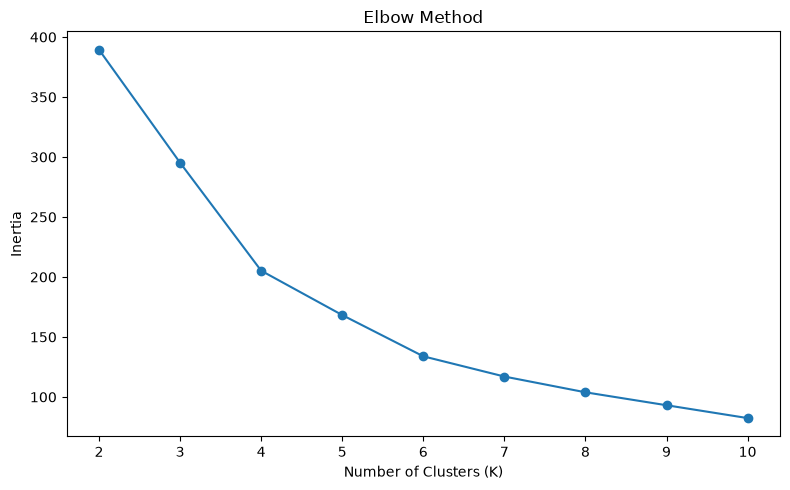

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.xticks(k_values)

plt.tight_layout()

plt.savefig(
    "images/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Silhouette Score

The silhouette score measures how well each observation fits within its assigned cluster compared with other clusters.

The score ranges from -1 to 1.

Higher values generally indicate that observations are more appropriately separated into their assigned clusters.

In [15]:
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

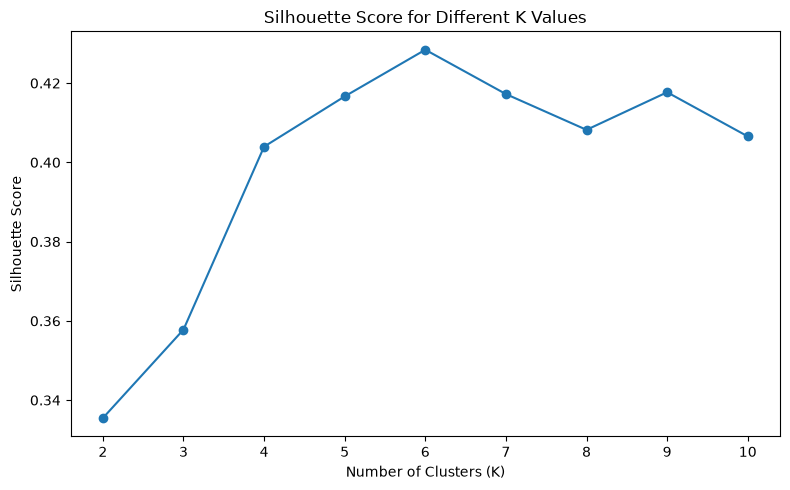

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(k_values)

plt.tight_layout()

plt.savefig(
    "images/silhouette_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
silhouette_results = pd.DataFrame({
    "K": k_values,
    "Silhouette Score": silhouette_scores
})

silhouette_results

,K,Silhouette Score
0,2,0.335472
1,3,0.357793
2,4,0.403958
3,5,0.416643
4,6,0.428417
5,7,0.417232
6,8,0.408207
7,9,0.417693
8,10,0.406554


## 8. Train the K-Means Model

Based on the silhouette score analysis, we will use **6 clusters** for the final K-Means model.

The model will assign each customer to one of the six discovered customer segments.

In [18]:
optimal_k = 6

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

cluster_labels[:10]

array([4, 4, 5, 4, 5, 4, 5, 4, 5, 4], dtype=int32)

### Assign Cluster Labels

The cluster labels are added to the original dataset so that we can analyze the characteristics of each customer segment.

In [19]:
df["Cluster"] = cluster_labels

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,5
3,4,Female,23,16,77,4
4,5,Female,31,17,40,5


### Cluster Distribution

We examine the number of customers assigned to each cluster.

In [20]:
df["Cluster"].value_counts().sort_index()

Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

## 9. Visualize Customer Segments

We can visualize the discovered customer segments using annual income and spending score.

Each point represents a customer, while the point's position indicates their annual income and spending score.

The color of each point represents its assigned cluster.

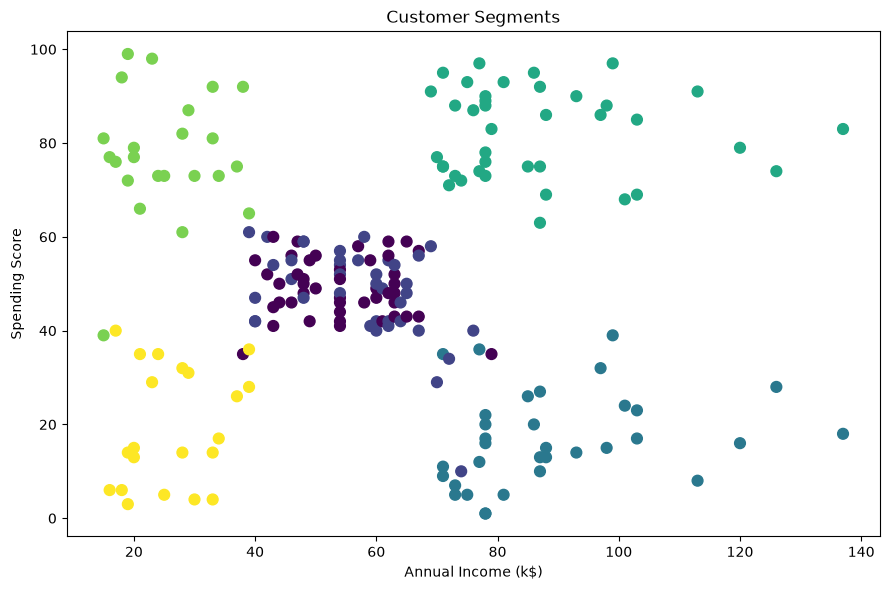

In [21]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    s=60
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customer Segments")

plt.tight_layout()

plt.savefig(
    "images/customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Cluster Centers

K-Means represents each cluster using a centroid, which is the center point of the observations assigned to that cluster.

The cluster centers help us understand the typical position of each customer segment.

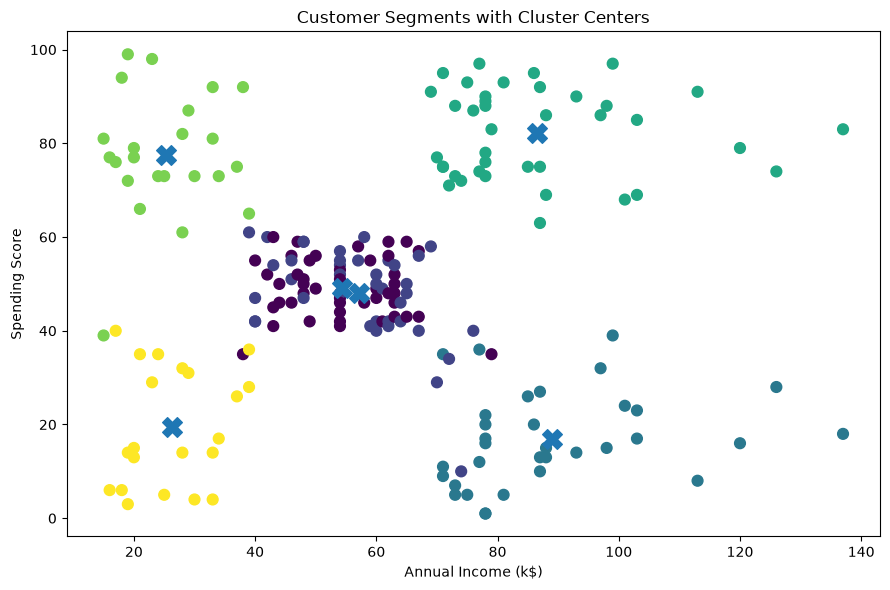

In [22]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    s=60
)

plt.scatter(
    centers[:, 1],
    centers[:, 2],
    marker="X",
    s=200
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customer Segments with Cluster Centers")

plt.tight_layout()
plt.show()

## 10. Cluster Analysis

To understand the characteristics of each customer segment, we calculate the average age, annual income, and spending score for each cluster.

This allows us to interpret the clusters based on their demographic and spending behavior.

In [23]:
cluster_summary = df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


### Cluster Sizes

We also examine the number of customers in each segment.

In [24]:
cluster_sizes = df["Cluster"].value_counts().sort_index()

cluster_sizes

Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

### Combined Cluster Summary

The following table combines the cluster size with the average characteristics of each customer segment.

In [25]:
cluster_summary = df.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_summary

,Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


## 11. Visualize Cluster Profiles

The average values of each feature can be compared across the six customer segments.

These visualizations help identify the demographic and spending characteristics that distinguish the clusters.

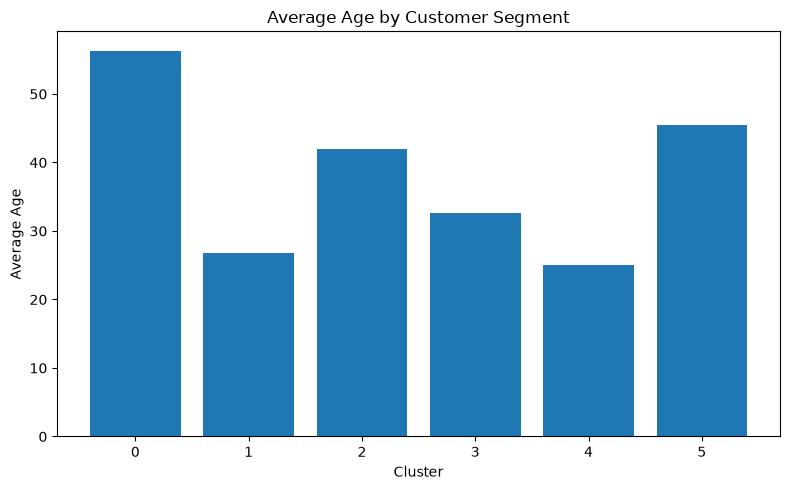

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_summary.index,
    cluster_summary["Average_Age"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Age")
plt.title("Average Age by Customer Segment")

plt.tight_layout()
plt.show()

### Average Annual Income

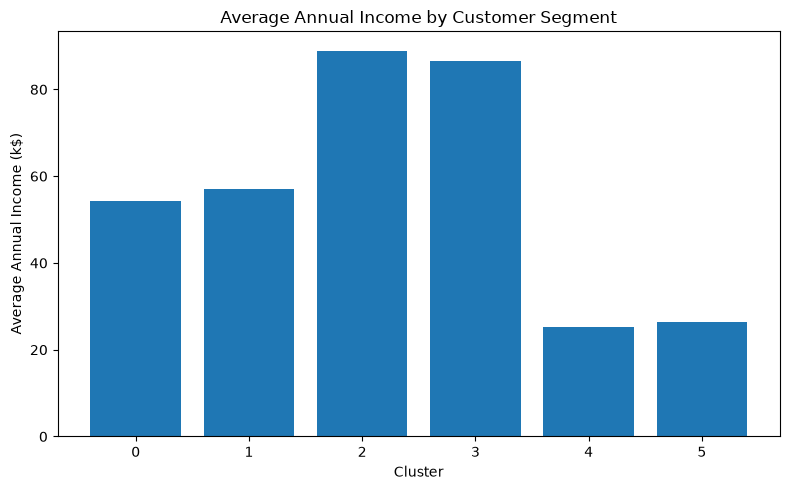

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_summary.index,
    cluster_summary["Average_Income"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Annual Income (k$)")
plt.title("Average Annual Income by Customer Segment")

plt.tight_layout()
plt.show()

### Average Spending Score

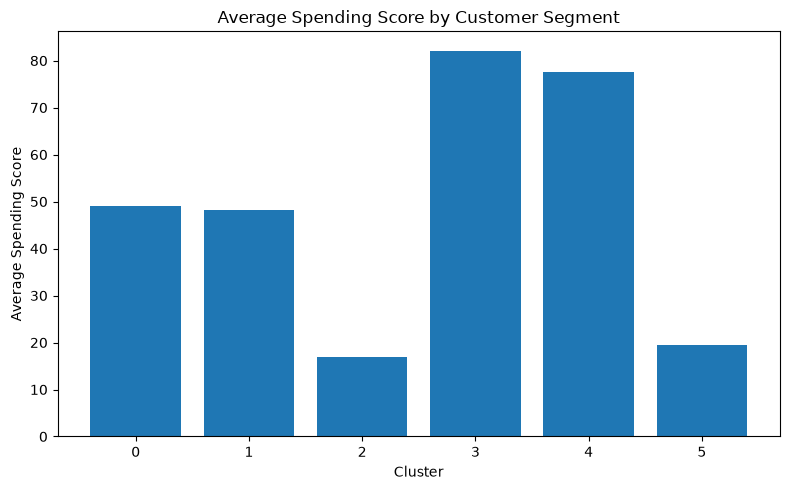

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_summary.index,
    cluster_summary["Average_Spending_Score"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Spending Score")
plt.title("Average Spending Score by Customer Segment")

plt.tight_layout()
plt.show()

## 12. PCA Visualization

Principal Component Analysis (PCA) is used here to reduce the three standardized features into two dimensions for visualization.

PCA is not used to train the K-Means model. The clustering model was trained using the original three standardized features.

In [29]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

X_pca[:5]

array([[-0.61572002, -1.76348088],
       [-1.66579271, -1.82074695],
       [ 0.33786191, -1.67479894],
       [-1.45657325, -1.77242992],
       [-0.03846521, -1.66274012]])

In [30]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.44266167 0.33308378]
Total explained variance: 0.7757454566976747


The first two principal components explain approximately **77.57% of the total variance** in the standardized dataset.

This means the two-dimensional PCA visualization preserves a substantial portion of the information contained in the original three features, while some information is lost through dimensionality reduction.

### Customer Segments in PCA Space

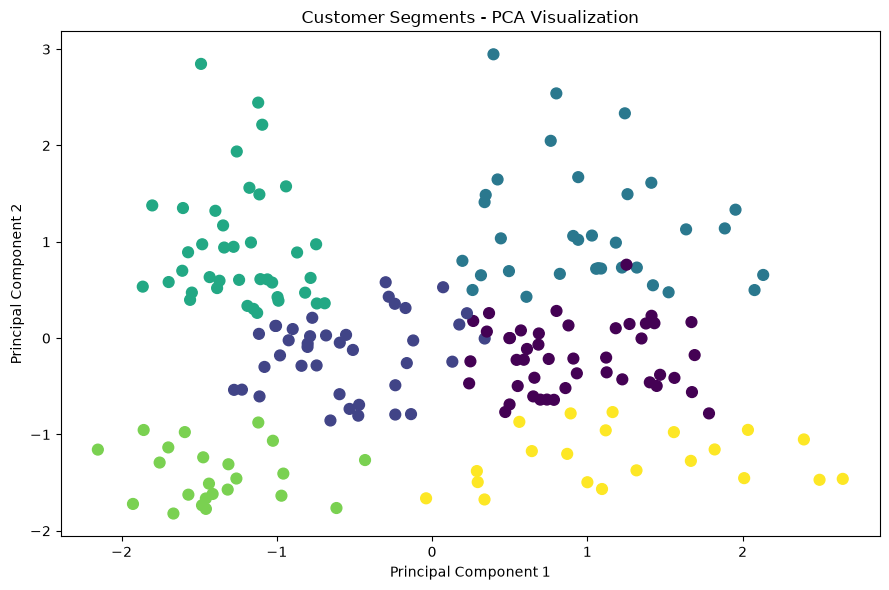

In [31]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments - PCA Visualization")

plt.tight_layout()

plt.savefig(
    "images/pca_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Final Cluster Summary

The table below summarizes the size and average characteristics of each customer segment.

The cluster numbers are algorithm-generated identifiers rather than predefined customer categories. Their interpretation is based on the characteristics observed in each segment.

In [32]:
final_summary = cluster_summary.copy()

final_summary

,Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


## 14. Customer Segment Interpretation

The six clusters can be interpreted based on their average age, annual income, and spending score.

- **Cluster 0:** Older customers with moderate income and moderate spending.
- **Cluster 1:** Younger customers with moderate income and moderate spending.
- **Cluster 2:** Middle-aged customers with high income and low spending.
- **Cluster 3:** Younger customers with high income and high spending.
- **Cluster 4:** Younger customers with low income and high spending.
- **Cluster 5:** Middle-aged customers with low income and low spending.

These descriptions are based on the average characteristics of each cluster and are intended to make the discovered customer segments easier to interpret.

## 15. Conclusion

K-Means clustering was used to divide customers into six segments based on age, annual income, and spending score.

The Elbow Method and Silhouette Score were used to evaluate different values of K, with **K = 6** providing the highest silhouette score among the tested values.

The resulting clusters revealed distinct customer profiles based on their demographic and spending characteristics.

This project demonstrates how unsupervised machine learning can be used to discover patterns and customer segments without predefined target labels.